# Step 5. EDA & Visualization — Weather Conditions Analysis

## Objective

This notebook explores how weather conditions are associated with arrival delays for flights departing from New York City airports in 2013.

We examine precipitation, wind speed, visibility, temperature, and humidity, and compare arrival delay patterns under different weather conditions.

Weather observations were joined to flight records using the origin airport and hourly timestamp during Step 3.

This analysis is exploratory. The results do not establish that weather conditions directly cause arrival delays.

## 1. Load & Validate Data

Load the cleaned flight dataset and examine the completeness of weather variables.

Weather observations were joined to flights using `origin` and `time_hour` with a many-to-one left join.

Flights with missing arrival delays were excluded during Step 3, while missing weather values were retained.

Each weather analysis uses observations with valid values for the weather variable being examined.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

data_path = Path("data/cleaned/analysis_ready_flights.csv")
fig_dir = Path("results/figures")
table_dir = Path("results/tables")

fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

analysis = pd.read_csv(data_path)

weather_vars = [
    "temp", "dewp", "humid",
    "wind_speed", "precip", "visib"
]

required_cols = ["arr_delay", "origin", "time_hour"] + weather_vars

assert all(col in analysis.columns for col in required_cols)
assert analysis["arr_delay"].notna().all()

print("Dataset shape:", analysis.shape)
print("Total flights:", f"{len(analysis):,}")

weather_missing = pd.DataFrame({
    "Missing_Count": analysis[weather_vars].isna().sum(),
    "Missing_Pct": analysis[weather_vars].isna().mean() * 100,
    "Valid_Count": analysis[weather_vars].notna().sum()
})

display(weather_missing.round(2))

print("Origin airports:", sorted(analysis["origin"].unique()))

Dataset shape: (327346, 34)
Total flights: 327,346


,Missing_Count,Missing_Pct,Valid_Count
temp,1544,0.47,325802
dewp,1544,0.47,325802
humid,1544,0.47,325802
wind_speed,1605,0.49,325741
precip,1527,0.47,325819
visib,1527,0.47,325819


Origin airports: ['EWR', 'JFK', 'LGA']


## 2. Weather Descriptive Statistics

Summarize the distribution of weather variables, including temperature, humidity, wind speed, precipitation, and visibility.

Weather variables in the nycflights13 dataset use the following units:

- Temperature and dew point: degrees Fahrenheit
- Humidity: percentage
- Wind speed: miles per hour
- Precipitation: inches
- Visibility: miles

The statistics are calculated using available observations for each variable.

In [2]:
weather_summary = analysis[weather_vars].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(weather_summary.round(2))

# Check for invalid values
quality_checks = pd.DataFrame({
    "Negative_Values": [
        (analysis[col] < 0).sum()
        for col in weather_vars
    ],
    "Missing_Values": [
        analysis[col].isna().sum()
        for col in weather_vars
    ]
}, index=weather_vars)

display(quality_checks)

print("Note: Negative temperatures and dew points are valid.")

,temp,dewp,humid,wind_speed,precip,visib
count,325802.00,325802.00,325802.00,325741.00,325819.00,325819.00
mean,57.01,41.50,59.21,11.06,0.00,9.29
std,17.90,19.33,19.57,5.53,0.03,1.98
min,10.94,-9.94,12.74,0.00,0.00,0.00
10%,33.08,15.08,34.83,4.60,0.00,7.00
25%,42.08,26.06,43.74,6.90,0.00,10.00
50%,57.20,42.80,57.22,10.36,0.00,10.00
75%,71.96,57.92,74.67,14.96,0.00,10.00
90%,80.06,66.92,87.65,18.41,0.00,10.00
95%,84.02,69.98,92.96,20.71,0.01,10.00


,Negative_Values,Missing_Values
temp,0,1544
dewp,2722,1544
humid,0,1544
wind_speed,0,1605
precip,0,1527
visib,0,1527


Note: Negative temperatures and dew points are valid.


In [3]:
invalid_weather = {
    "humid": ((analysis["humid"] < 0) | (analysis["humid"] > 100)).sum(),
    "wind_speed": (analysis["wind_speed"] < 0).sum(),
    "precip": (analysis["precip"] < 0).sum(),
    "visib": (analysis["visib"] < 0).sum()
}

print("Potentially invalid weather values:")

for variable, count in invalid_weather.items():
    print(f"{variable}: {count:,}")

assert all(count == 0 for count in invalid_weather.values()), (
    "Review potentially invalid weather values before continuing."
)

Potentially invalid weather values:
humid: 0
wind_speed: 0
precip: 0
visib: 0


## 3. Precipitation and Arrival Delays

Compare arrival delays between flights with no recorded precipitation and flights with recorded precipitation.

- No Precipitation: precipitation = 0 inches
- Precipitation: precipitation > 0 inches

This classification measures recorded precipitation at the departure airport and observation hour. It does not identify precipitation type or conditions along the entire flight route.

In [4]:
precip_data = analysis.loc[
    analysis["precip"].notna()
].copy()

precip_data["precip_group"] = np.where(
    precip_data["precip"] > 0,
    "Precipitation",
    "No Precipitation"
)

precip_order = ["No Precipitation", "Precipitation"]

precip_stats = (
    precip_data.groupby("precip_group")["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(precip_order)
)

display(precip_stats.round(2))

,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
precip_group,,,,,,,
No Precipitation,304877,5.05,-6.0,42.47,22.05,7.57,2.66
Precipitation,20942,33.54,13.0,63.38,47.69,21.94,8.99


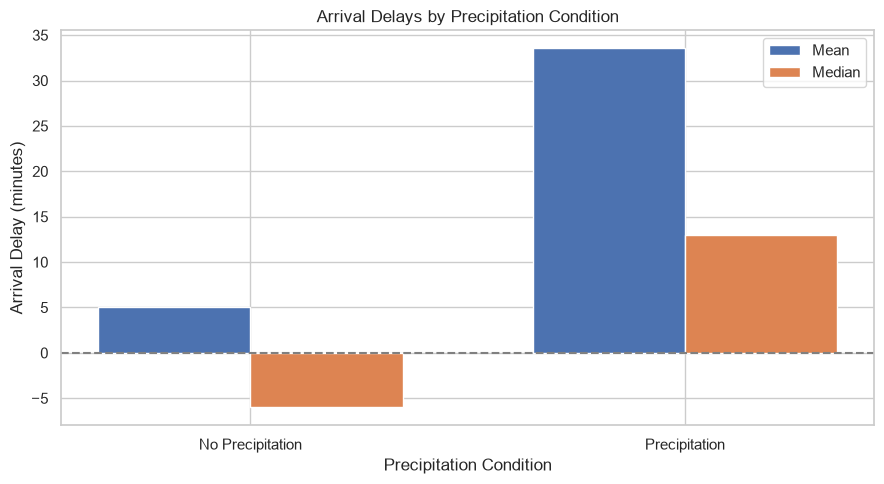

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(precip_order))
width = 0.35

ax.bar(
    x - width / 2,
    precip_stats["Mean"],
    width,
    label="Mean"
)

ax.bar(
    x + width / 2,
    precip_stats["Median"],
    width,
    label="Median"
)

ax.set_xticks(x)
ax.set_xticklabels(precip_order)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delays by Precipitation Condition",
    xlabel="Precipitation Condition",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "weather_precipitation_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 4. Wind Speed and Arrival Delays

Explore how arrival delays differ across wind speed groups.

Wind speed is measured in miles per hour. The groups are exploratory categories used to compare delay patterns.

Flights with missing wind speed values are excluded from this specific analysis.

In [6]:
wind_data = analysis.loc[
    analysis["wind_speed"].notna()
    & (analysis["wind_speed"] >= 0)
].copy()

wind_bins = [-0.001, 5, 10, 15, 20, np.inf]

wind_labels = [
    "0-5",
    ">5-10",
    ">10-15",
    ">15-20",
    ">20"
]

wind_data["wind_group"] = pd.cut(
    wind_data["wind_speed"],
    bins=wind_bins,
    labels=wind_labels
)

wind_stats = (
    wind_data.groupby("wind_group", observed=True)["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(wind_labels)
)

display(wind_stats.round(2))

,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
wind_group,,,,,,,
0-5,40552,3.52,-7.0,41.78,19.57,6.84,2.61
>5-10,105252,4.98,-6.0,42.58,22.11,7.57,2.69
>10-15,116608,7.24,-5.0,45.49,24.17,8.87,3.17
>15-20,43412,10.26,-3.0,47.03,26.97,9.83,3.60
>20,19917,14.35,0.0,49.32,30.70,11.63,4.24


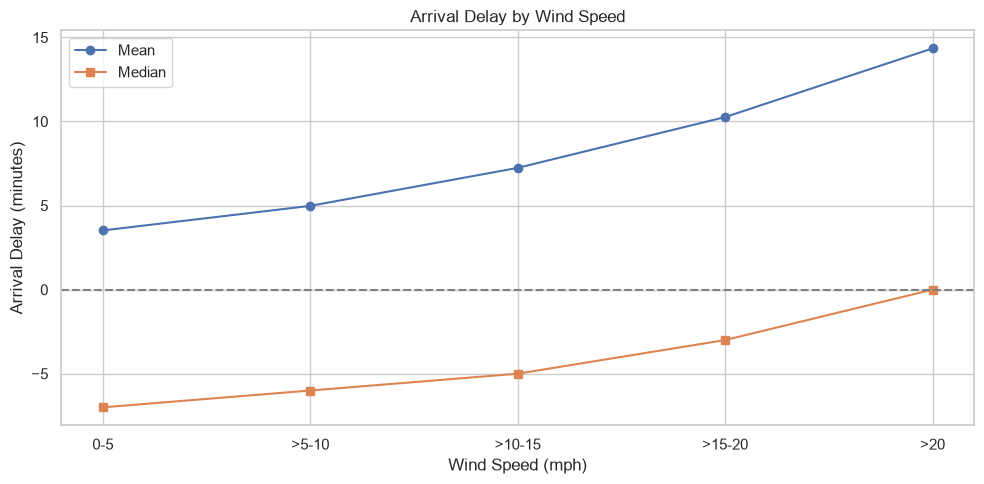

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    wind_stats.index,
    wind_stats["Mean"],
    marker="o",
    label="Mean"
)

ax.plot(
    wind_stats.index,
    wind_stats["Median"],
    marker="s",
    label="Median"
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay by Wind Speed",
    xlabel="Wind Speed (mph)",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "weather_wind_speed_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 5. Visibility and Arrival Delays

Compare arrival delays across visibility groups.

Visibility is measured in miles. Lower visibility may reflect conditions such as fog, precipitation, or other atmospheric factors.

The groups are exploratory and are not official aviation operating categories.

In [8]:
visibility_data = analysis.loc[
    analysis["visib"].notna()
    & (analysis["visib"] >= 0)
].copy()

visibility_bins = [-0.001, 1, 3, 5, 10, np.inf]

visibility_labels = [
    "0-1",
    ">1-3",
    ">3-5",
    ">5-10",
    ">10"
]

visibility_data["visibility_group"] = pd.cut(
    visibility_data["visib"],
    bins=visibility_bins,
    labels=visibility_labels
)

visibility_stats = (
    visibility_data.groupby(
        "visibility_group", observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(visibility_labels)
)

display(visibility_stats.round(2))

,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
visibility_group,,,,,,,
0-1,4942.0,34.38,12.0,69.03,46.94,22.64,9.75
>1-3,10359.0,25.96,9.0,58.14,42.42,17.13,6.53
>3-5,6650.0,18.54,2.0,52.61,34.63,14.23,5.38
>5-10,303868.0,5.53,-5.0,43.08,22.45,7.84,2.79
>10,NaN,NaN,NaN,NaN,NaN,NaN,NaN


fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    visibility_stats.index,
    visibility_stats["Mean"],
    color="steelblue"
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Mean Arrival Delay by Visibility",
    xlabel="Visibility (miles)",
    ylabel="Mean Arrival Delay (minutes)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "weather_visibility_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 6. Temperature and Arrival Delays

Examine arrival delays across temperature groups.

Temperature is measured in degrees Fahrenheit. The categories are created for exploratory comparisons.

Temperature may be related to season and other weather conditions, so differences should not be interpreted as causal effects.

In [9]:
temp_data = analysis.loc[
    analysis["temp"].notna()
].copy()

temp_bins = [-np.inf, 32, 50, 70, 85, np.inf]

temp_labels = [
    "32 or below",
    ">32-50",
    ">50-70",
    ">70-85",
    ">85"
]

temp_data["temp_group"] = pd.cut(
    temp_data["temp"],
    bins=temp_bins,
    labels=temp_labels
)

temp_stats = (
    temp_data.groupby("temp_group", observed=True)["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(temp_labels)
)

display(temp_stats.round(2))

,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
temp_group,,,,,,,
32 or below,29438,8.48,-2.0,42.90,25.03,8.00,2.77
>32-50,98643,5.64,-4.0,39.65,23.13,7.19,2.22
>50-70,106301,3.73,-6.0,41.73,20.73,7.08,2.50
>70-85,79011,10.89,-5.0,51.87,26.83,11.35,4.58
>85,12409,14.43,-4.0,56.54,30.57,13.91,5.71


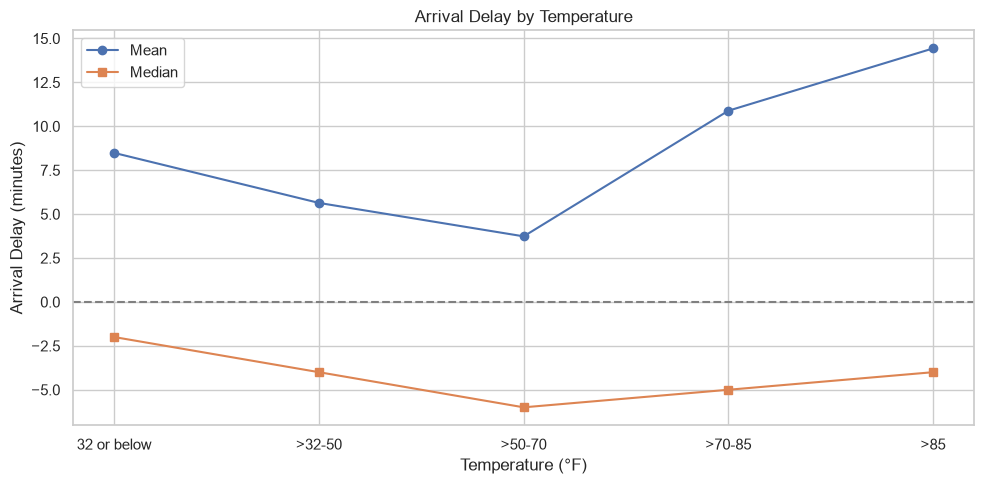

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    temp_stats.index,
    temp_stats["Mean"],
    marker="o",
    label="Mean"
)

ax.plot(
    temp_stats.index,
    temp_stats["Median"],
    marker="s",
    label="Median"
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Arrival Delay by Temperature",
    xlabel="Temperature (°F)",
    ylabel="Arrival Delay (minutes)"
)

ax.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "weather_temperature_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Humidity and Arrival Delays

Explore arrival delay patterns across humidity groups.

Humidity is measured as a percentage. These comparisons help identify possible relationships between atmospheric moisture and arrival delays.

In [11]:
humidity_data = analysis.loc[
    analysis["humid"].between(0, 100)
].copy()

humidity_bins = [-0.001, 40, 60, 80, 100]

humidity_labels = [
    "0-40",
    ">40-60",
    ">60-80",
    ">80-100"
]

humidity_data["humidity_group"] = pd.cut(
    humidity_data["humid"],
    bins=humidity_bins,
    labels=humidity_labels
)

humidity_stats = (
    humidity_data.groupby(
        "humidity_group", observed=True
    )["arr_delay"]
    .agg(
        Flights="count",
        Mean="mean",
        Median="median",
        Std="std",
        Delay_Over_15_Pct=lambda x: (x > 15).mean() * 100,
        Delay_Over_60_Pct=lambda x: (x > 60).mean() * 100,
        Delay_Over_120_Pct=lambda x: (x > 120).mean() * 100
    )
    .reindex(humidity_labels)
)

display(humidity_stats.round(2))

,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
humidity_group,,,,,,,
0-40,59231,2.26,-6.0,36.25,20.21,5.74,1.75
>40-60,118368,1.94,-7.0,38.00,19.24,5.84,1.96
>60-80,86619,7.13,-5.0,46.17,23.83,8.85,3.16
>80-100,61584,20.47,2.0,57.13,35.44,15.74,6.35


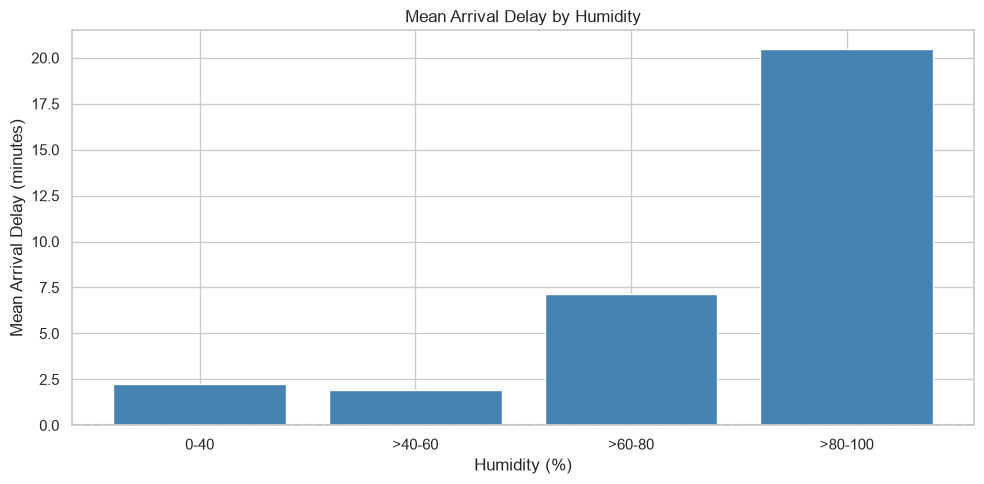

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    humidity_stats.index,
    humidity_stats["Mean"],
    color="steelblue"
)

ax.axhline(0, color="gray", linestyle="--")

ax.set(
    title="Mean Arrival Delay by Humidity",
    xlabel="Humidity (%)",
    ylabel="Mean Arrival Delay (minutes)"
)

plt.tight_layout()

plt.savefig(
    fig_dir / "weather_humidity_delay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Weather Conditions and Severe Delays

Compare moderate and severe arrival delay rates under different weather conditions.

The analysis uses three thresholds:

- More than 15 minutes
- More than 60 minutes
- More than 120 minutes

The sample size for each comparison depends on the availability of the corresponding weather variable.

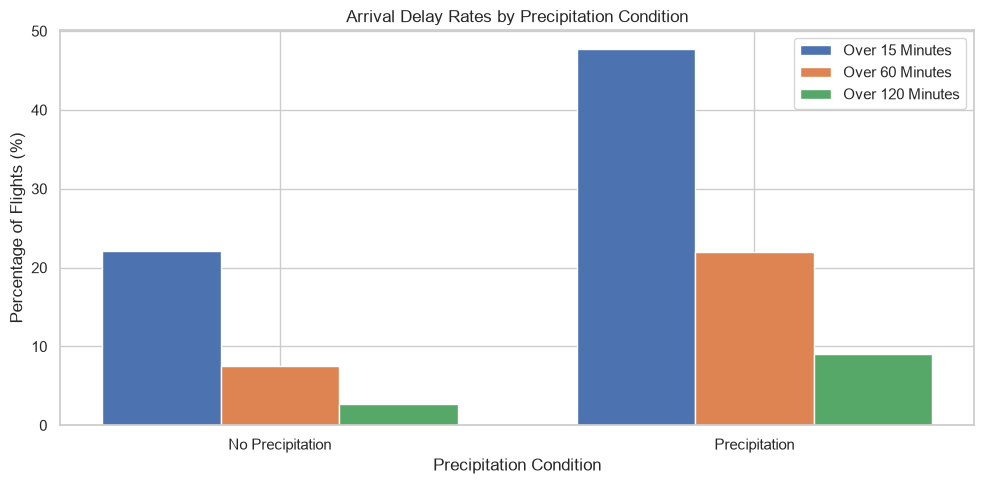

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(precip_order))
width = 0.25

ax.bar(
    x - width,
    precip_stats["Delay_Over_15_Pct"],
    width,
    label="Over 15 Minutes"
)

ax.bar(
    x,
    precip_stats["Delay_Over_60_Pct"],
    width,
    label="Over 60 Minutes"
)

ax.bar(
    x + width,
    precip_stats["Delay_Over_120_Pct"],
    width,
    label="Over 120 Minutes"
)

ax.set_xticks(x)
ax.set_xticklabels(precip_order)

ax.set(
    title="Arrival Delay Rates by Precipitation Condition",
    xlabel="Precipitation Condition",
    ylabel="Percentage of Flights (%)"
)

ax.legend()
plt.tight_layout()

plt.savefig(
    fig_dir / "weather_precipitation_delay_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Weather Correlations

Calculate Pearson correlations between weather variables and arrival delay.

Each correlation uses flights with valid observations for the two variables being compared.

These correlations measure linear associations only and do not control for other factors.

In [14]:
correlation_results = []

for variable in weather_vars:
    valid = analysis[[variable, "arr_delay"]].dropna()

    correlation_results.append({
        "Variable": variable,
        "Flights": len(valid),
        "Pearson_r": valid[variable].corr(valid["arr_delay"])
    })

weather_correlations = pd.DataFrame(correlation_results)

display(weather_correlations.round(4))

,Variable,Flights,Pearson_r
0,temp,325802,0.0330
1,dewp,325802,0.0869
2,humid,325802,0.1414
3,wind_speed,325741,0.0641
4,precip,325819,0.1113
5,visib,325819,-0.1355


## 10. Save Results

Export weather descriptive statistics, missing-value summaries, group comparisons, and correlations for use in the project report.

In [15]:
tables = {
    "weather_descriptive_statistics": weather_summary,
    "weather_missing_values": weather_missing,
    "weather_precipitation_statistics": precip_stats,
    "weather_wind_statistics": wind_stats,
    "weather_visibility_statistics": visibility_stats,
    "weather_temperature_statistics": temp_stats,
    "weather_humidity_statistics": humidity_stats,
    "weather_correlations": weather_correlations
}

for name, table in tables.items():
    table.to_csv(table_dir / f"{name}.csv")

print(f"Saved {len(tables)} weather analysis tables.")
print("Figures saved in:", fig_dir)

Saved 8 weather analysis tables.
Figures saved in: results/figures


In [16]:
print("=== WEATHER EDA SUMMARY ===")

print("\nPrecipitation:")
display(precip_stats.round(2))

print("\nWind Speed:")
display(wind_stats.round(2))

print("\nVisibility:")
display(visibility_stats.round(2))

print("\nTemperature:")
display(temp_stats.round(2))

print("\nHumidity:")
display(humidity_stats.round(2))

print("\nPearson Correlations:")
display(weather_correlations.round(4))

print("\nWeather Missing Values:")
display(weather_missing.round(2))

=== WEATHER EDA SUMMARY ===

Precipitation:


,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
precip_group,,,,,,,
No Precipitation,304877,5.05,-6.0,42.47,22.05,7.57,2.66
Precipitation,20942,33.54,13.0,63.38,47.69,21.94,8.99



Wind Speed:


,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
wind_group,,,,,,,
0-5,40552,3.52,-7.0,41.78,19.57,6.84,2.61
>5-10,105252,4.98,-6.0,42.58,22.11,7.57,2.69
>10-15,116608,7.24,-5.0,45.49,24.17,8.87,3.17
>15-20,43412,10.26,-3.0,47.03,26.97,9.83,3.60
>20,19917,14.35,0.0,49.32,30.70,11.63,4.24



Visibility:


,Flights,Mean,Median,Std,Delay_Over_15_Pct,Delay_Over_60_Pct,Delay_Over_120_Pct
visibility_group,,,,,,,
0-1,4942.0,34.38,12.0,69.03,46.94,22.64,9.75
>1-3,10359.0,25.96,9.0,58.14,42.42,17.13,6.53
>3-5,6650.0,18.54,2.0,52.61,34.63,14.23,5.38
>5-10,303868.0,5.53,-5.0,43.08,22.45,7.84,2.79
>10,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (4 outputs left out)


Pearson Correlations:


,Variable,Flights,Pearson_r
0,temp,325802,0.0330
1,dewp,325802,0.0869
2,humid,325802,0.1414
3,wind_speed,325741,0.0641
4,precip,325819,0.1113
5,visib,325819,-0.1355



Weather Missing Values:


,Missing_Count,Missing_Pct,Valid_Count
temp,1544,0.47,325802
dewp,1544,0.47,325802
humid,1544,0.47,325802
wind_speed,1605,0.49,325741
precip,1527,0.47,325819
visib,1527,0.47,325819


## 11. Key Findings and Limitations

### Key Findings

Weather conditions showed noticeable differences in arrival delays across the groups examined.

Flights with recorded precipitation had a mean arrival delay of 33.54 minutes, compared with 5.05 minutes for flights without precipitation. The percentage of flights delayed more than 60 minutes was also higher with precipitation (21.94% vs. 7.57%).

Lower visibility was associated with greater arrival delays. Flights with visibility of 1 mile or less had a mean delay of 34.38 minutes, compared with 5.53 minutes for flights with visibility above 5 and up to 10 miles.

Mean arrival delays generally increased across the wind speed groups, from 3.52 minutes at 0–5 mph to 14.35 minutes above 20 mph.

Higher humidity was also associated with longer delays. Flights with humidity above 80% had a mean arrival delay of 20.47 minutes, while flights with humidity between 40% and 60% averaged 1.94 minutes.

Temperature showed a less consistent pattern. Flights above 85°F had a mean delay of 14.43 minutes, while flights between 50°F and 70°F averaged 3.73 minutes.

Pearson correlations with arrival delay were relatively weak for all weather variables. Humidity (r = 0.1414), visibility (r = −0.1355), and precipitation (r = 0.1113) had the largest absolute correlations among the variables examined.

Overall, precipitation, low visibility, and high humidity were associated with greater arrival delays in this dataset. However, the correlations suggest that individual weather variables have limited linear relationships with arrival delay.

### Limitations

This analysis only includes flights departing from New York City airports in 2013, so the findings may not represent current flight operations.

Weather observations were matched to flights using the departure airport and hourly timestamp. These observations may not fully represent conditions at the exact departure time, destination airport, or along the flight route.

Weather variables had approximately 0.47%–0.49% missing values, resulting in slightly different sample sizes across analyses.

Weather conditions may also be associated with season, airport, airline, and scheduled departure time. These factors were not controlled for in this exploratory analysis.

The weather groups were created for descriptive comparisons and are not official aviation operating categories.

Extreme delays may influence mean arrival delays, and the observed relationships do not establish causation.

### Data Preparation and Quality Notes

This analysis uses the cleaned flight dataset prepared in Step 3, containing 327,346 flights.

Flight and weather records were merged using `origin` and `time_hour` with a many-to-one left join. The merge preserved the flight count.

Flights with missing arrival delay values were excluded during data cleaning, while missing weather values were retained.

Each weather analysis used flights with valid observations for the corresponding weather variable. The original continuous weather variables were also used to calculate Pearson correlations.

Weather conditions were grouped into exploratory categories to compare mean delays, median delays, and the percentages of flights delayed more than 15, 60, and 120 minutes.